# Land-Cover Classification on EuroSAT

The goal of this notebook is to classify Sentinel-2 satellite image patches into 10 land-cover classes
(forest, river, residential area, ...) using the RGB version of the EuroSAT dataset (27,000 images of 64×64 pixels).
I compare three models: a CNN trained from scratch, the same CNN with data augmentation, and a fine-tuned
EfficientNetB0 pretrained on ImageNet, then look at the errors and at Grad-CAM explanations of the best model.

In [1]:
import os
import shutil
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

SEED = 42
BATCH_SIZE = 64
keras.utils.set_random_seed(SEED)  # seeds Python, NumPy and TensorFlow
os.makedirs("figures", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Data

The RGB images are downloaded from the [official Zenodo record](https://zenodo.org/records/7711810)
(the download link used by `tensorflow_datasets` is offline). The zip has one folder per class.
The dataset has no predefined split, so I load all images into memory (about 330 MB) and make my own
stratified **70 / 15 / 15** train / validation / test split with a fixed seed.

In [2]:
DATA_URL = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip"
DATA_DIR = "EuroSAT_RGB"

if not os.path.exists(DATA_DIR):
    urllib.request.urlretrieve(DATA_URL, "EuroSAT_RGB.zip")
    with zipfile.ZipFile("EuroSAT_RGB.zip") as zf:
        zf.extractall()

class_names = sorted(os.listdir(DATA_DIR))
images, labels = [], []
for label, name in enumerate(class_names):
    for filename in sorted(os.listdir(os.path.join(DATA_DIR, name))):
        images.append(np.array(Image.open(os.path.join(DATA_DIR, name, filename))))
        labels.append(label)
images, labels = np.stack(images), np.array(labels)

print("Images:", images.shape, images.dtype)
print("Classes:", class_names)

Images: (27000, 64, 64, 3) uint8
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [3]:
# 70% train, then the remaining 30% is cut in half: 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    images, labels, test_size=0.30, stratify=labels, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

counts = pd.DataFrame({
    "train": np.bincount(y_train),
    "val": np.bincount(y_val),
    "test": np.bincount(y_test),
}, index=class_names)
counts.loc["total"] = counts.sum()
counts

,train,val,test
AnnualCrop,2100,450,450
Forest,2100,450,450
HerbaceousVegetation,2100,450,450
Highway,1750,375,375
Industrial,1750,375,375
Pasture,1400,300,300
PermanentCrop,1750,375,375
Residential,2100,450,450
River,1750,375,375
SeaLake,2100,450,450


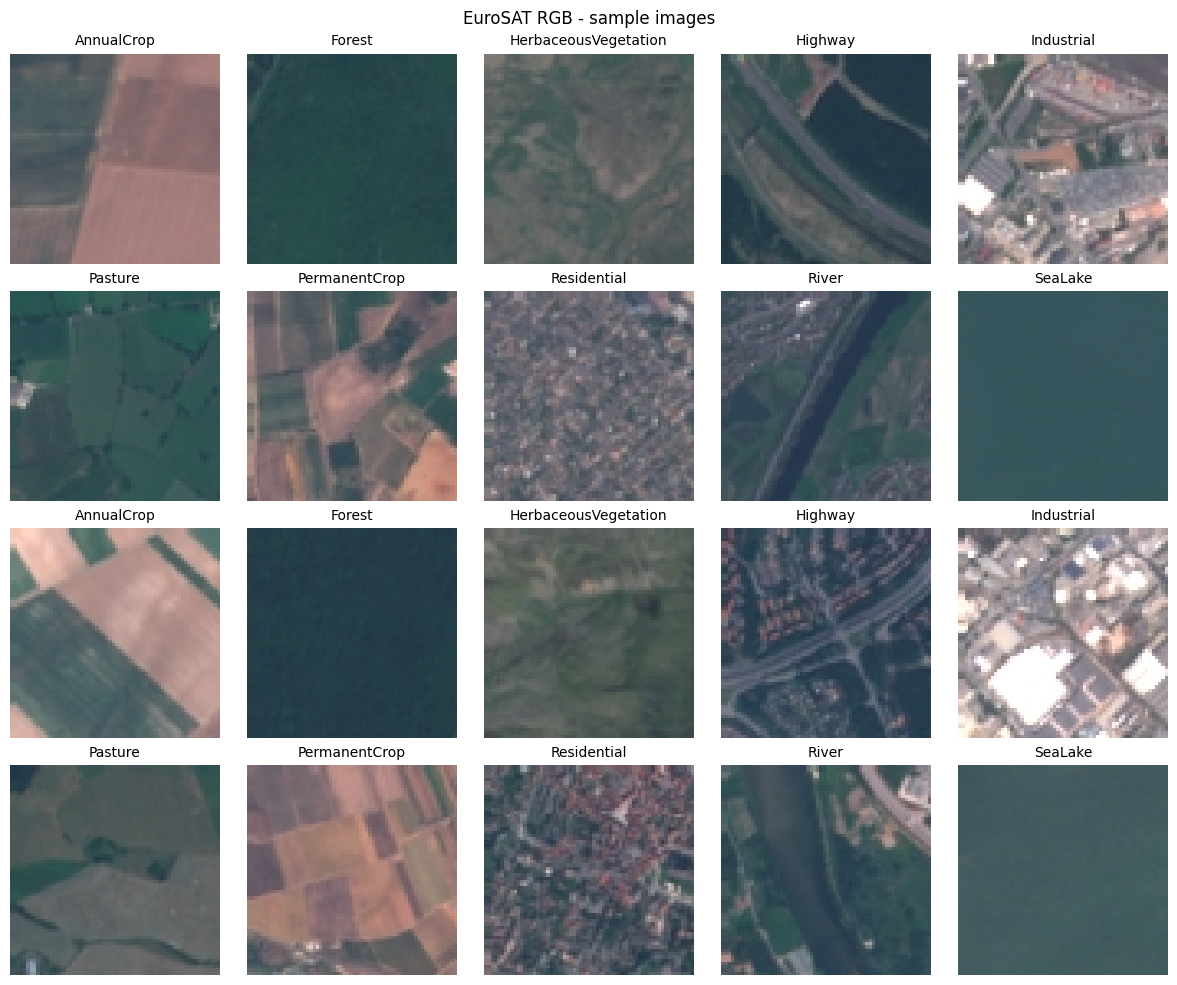

In [4]:
# Two examples per class
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for i, ax in enumerate(axes.flat):
    class_id, example = i % 10, i // 10
    idx = np.where(y_train == class_id)[0][example]
    ax.imshow(X_train[idx])
    ax.set_title(class_names[class_id], fontsize=10)
    ax.axis("off")
plt.suptitle("EuroSAT RGB - sample images")
plt.tight_layout()
plt.savefig("figures/sample_images.png", dpi=150)
plt.show()

## 2. Preprocessing with `tf.data`

Each split becomes a `tf.data` pipeline: shuffle (train only), batch, resize, scale pixels to [0, 1] and prefetch.
The CNNs use the native 64×64 resolution, while EfficientNetB0 gets images upscaled to 224×224,
the resolution it was pretrained on.

In [5]:
AUTOTUNE = tf.data.AUTOTUNE
CNN_SIZE = 64   # native EuroSAT resolution
TL_SIZE = 224   # EfficientNetB0 input size

def make_dataset(images, labels, img_size, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if shuffle:
        ds = ds.shuffle(len(images), seed=SEED)
    ds = ds.batch(BATCH_SIZE)
    # resizing whole batches is faster than resizing images one by one
    ds = ds.map(lambda x, y: (tf.image.resize(tf.cast(x, tf.float32), (img_size, img_size)) / 255.0, y),
                num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(X_train, y_train, CNN_SIZE, shuffle=True)
val_ds = make_dataset(X_val, y_val, CNN_SIZE)
test_ds = make_dataset(X_test, y_test, CNN_SIZE)

batch_images, batch_labels = next(iter(train_ds))
print(batch_images.shape, batch_labels.shape, float(tf.reduce_min(batch_images)), float(tf.reduce_max(batch_images)))

(64, 64, 64, 3) (64,) 0.0784313753247261 1.0


In [6]:
def plot_history(history, title, filename, fine_tune_start=None):
    """Plot train/validation accuracy and loss from a Keras history dict."""
    epochs = range(1, len(history["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        ax.plot(epochs, history[metric], label="train")
        ax.plot(epochs, history["val_" + metric], label="validation")
        if fine_tune_start:
            ax.axvline(fine_tune_start + 0.5, color="gray", linestyle="--", label="start of fine-tuning")
        ax.set_title(f"{title} - {metric}")
        ax.set_xlabel("epoch")
        ax.legend()
    plt.tight_layout()
    plt.savefig(f"figures/{filename}", dpi=150)
    plt.show()

# Stop when validation loss has not improved for 5 epochs and keep the best weights.
# A new callback is created for every fit(): a reused one would remember the best loss of the previous model.
def early_stop():
    return keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

EPOCHS = 15

## 3. Model 1: baseline CNN from scratch

Four Conv2D + MaxPooling blocks (64 → 32 → 16 → 8 → 4 pixels), then dropout and a small dense head.
The same function is reused for Model 2 so that the only difference between the two is the augmentation.

In [7]:
def build_cnn(augmentation=None):
    inputs = keras.Input(shape=(CNN_SIZE, CNN_SIZE, 3))
    x = inputs if augmentation is None else augmentation(inputs)
    for filters in [32, 64, 128, 128]:
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(class_names), activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

cnn_model = build_cnn()
cnn_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 504,394 (1.92 MB)

 Trainable params: 504,394 (1.92 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 24s 48ms/step - accuracy: 0.4176 - loss: 1.4716 - val_accuracy: 0.5948 - val_loss: 1.1754
Epoch 2/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.6512 - loss: 0.9588 - val_accuracy: 0.7415 - val_loss: 0.7179
Epoch 3/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.7236 - loss: 0.7727 - val_accuracy: 0.6363 - val_loss: 0.9441
Epoch 4/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.7529 - loss: 0.6876 - val_accuracy: 0.6832 - val_loss: 0.9087
Epoch 5/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.7810 - loss: 0.6139 - val_accuracy: 0.8178 - val_loss: 0.5021
Epoch 6/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8062 - loss: 0.5508 - val_accuracy: 0.8240 - val_loss: 0.4865
Epoch 7/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8206 - loss: 0.5157 - val_accuracy: 0.8254 - val_loss: 0.4812
Epoch 8/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8347 - loss: 0.4715 - val_acc

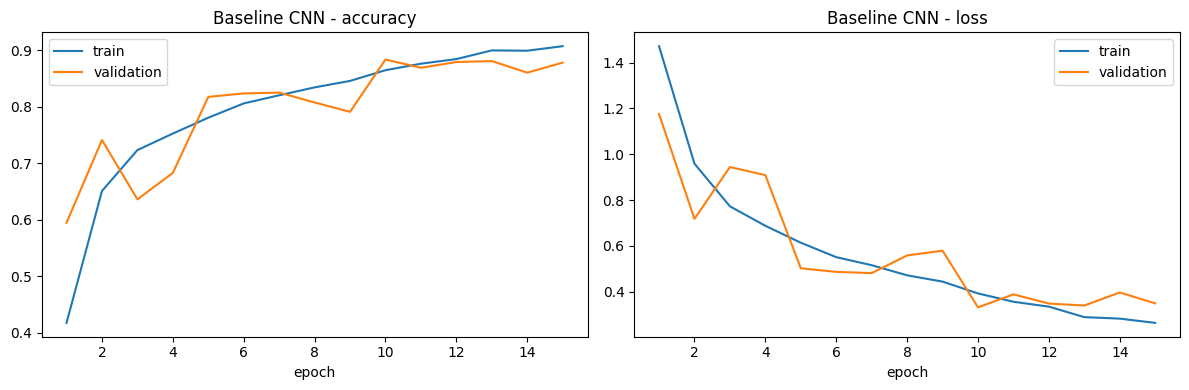

In [8]:
cnn_history = cnn_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[early_stop()])
plot_history(cnn_history.history, "Baseline CNN", "curves_baseline_cnn.png")

## 4. Model 2: baseline CNN + data augmentation

Satellite images have no "up" direction, so random flips and rotations create realistic new training images.
The augmentation layers are part of the model and are only active during training.

Epoch 1/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.4087 - loss: 1.5255 - val_accuracy: 0.6272 - val_loss: 1.0633
Epoch 2/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.6343 - loss: 1.0136 - val_accuracy: 0.6802 - val_loss: 0.8940
Epoch 3/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.7061 - loss: 0.8297 - val_accuracy: 0.6800 - val_loss: 0.8829
Epoch 4/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.7398 - loss: 0.7325 - val_accuracy: 0.6928 - val_loss: 0.8966
Epoch 5/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.7549 - loss: 0.6883 - val_accuracy: 0.7363 - val_loss: 0.7291
Epoch 6/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.7707 - loss: 0.6459 - val_accuracy: 0.7304 - val_loss: 0.7974
Epoch 7/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.7838 - loss: 0.6109 - val_accuracy: 0.7373 - val_loss: 0.7223
Epoch 8/15
296/296 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.7930 - loss: 0.5850 - val_acc

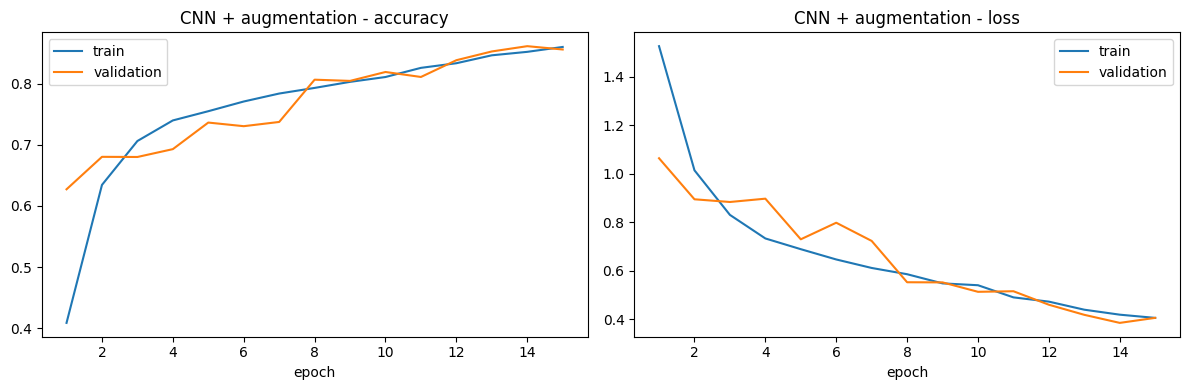

In [9]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),  # up to +/- 90 degrees
], name="augmentation")

aug_model = build_cnn(augmentation)
aug_history = aug_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[early_stop()])
plot_history(aug_history.history, "CNN + augmentation", "curves_cnn_augmentation.png")

## 5. Model 3: transfer learning with EfficientNetB0

Two phases:
1. **Feature extraction**: the ImageNet-pretrained base is frozen and only the new classification head is trained.
2. **Fine-tuning**: the top layers of the base are unfrozen and trained with a 10× lower learning rate,
   so the pretrained features are adapted without being destroyed. BatchNorm layers stay frozen, as recommended by Keras.

In [10]:
tl_train_ds = make_dataset(X_train, y_train, TL_SIZE, shuffle=True)
tl_val_ds = make_dataset(X_val, y_val, TL_SIZE)
tl_test_ds = make_dataset(X_test, y_test, TL_SIZE)

inputs = keras.Input(shape=(TL_SIZE, TL_SIZE, 3))
x = layers.Rescaling(255.0)(inputs)  # Keras' EfficientNet expects 0-255 pixels and normalizes them itself
base_model = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_tensor=x)
base_model.trainable = False

x = layers.GlobalAveragePooling2D()(base_model.output)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
tl_model = keras.Model(inputs, outputs)

tl_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("Trainable weights (head only):", len(tl_model.trainable_weights))

Trainable weights (head only): 2


In [11]:
HEAD_EPOCHS = 5
head_history = tl_model.fit(tl_train_ds, validation_data=tl_val_ds, epochs=HEAD_EPOCHS, callbacks=[early_stop()])

Epoch 1/5
296/296 ━━━━━━━━━━━━━━━━━━━━ 87s 195ms/step - accuracy: 0.8436 - loss: 0.5585 - val_accuracy: 0.9180 - val_loss: 0.2716
Epoch 2/5
296/296 ━━━━━━━━━━━━━━━━━━━━ 26s 88ms/step - accuracy: 0.9226 - loss: 0.2498 - val_accuracy: 0.9328 - val_loss: 0.2087
Epoch 3/5
296/296 ━━━━━━━━━━━━━━━━━━━━ 25s 84ms/step - accuracy: 0.9351 - loss: 0.2081 - val_accuracy: 0.9402 - val_loss: 0.1803
Epoch 4/5
296/296 ━━━━━━━━━━━━━━━━━━━━ 25s 84ms/step - accuracy: 0.9405 - loss: 0.1859 - val_accuracy: 0.9464 - val_loss: 0.1663
Epoch 5/5
296/296 ━━━━━━━━━━━━━━━━━━━━ 25s 85ms/step - accuracy: 0.9437 - loss: 0.1765 - val_accuracy: 0.9474 - val_loss: 0.1544


Trainable weights (head + top of base): 22
Epoch 1/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 85s 191ms/step - accuracy: 0.9515 - loss: 0.1434 - val_accuracy: 0.9541 - val_loss: 0.1226
Epoch 2/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 39s 103ms/step - accuracy: 0.9634 - loss: 0.1023 - val_accuracy: 0.9654 - val_loss: 0.0982
Epoch 3/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 40s 100ms/step - accuracy: 0.9741 - loss: 0.0751 - val_accuracy: 0.9659 - val_loss: 0.0995
Epoch 4/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 30s 101ms/step - accuracy: 0.9785 - loss: 0.0655 - val_accuracy: 0.9667 - val_loss: 0.0930
Epoch 5/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 41s 101ms/step - accuracy: 0.9828 - loss: 0.0518 - val_accuracy: 0.9672 - val_loss: 0.0973
Epoch 6/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 30s 102ms/step - accuracy: 0.9835 - loss: 0.0474 - val_accuracy: 0.9709 - val_loss: 0.0864
Epoch 7/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 29s 99ms/step - accuracy: 0.9872 - loss: 0.0392 - val_accuracy: 0.9706 - val_loss: 0.0874
Epoch 8/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 3

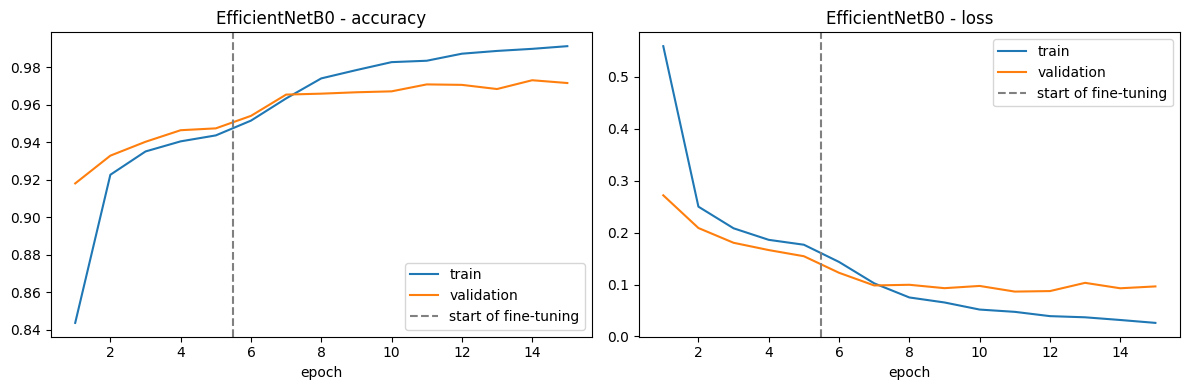

In [12]:
# Unfreeze the last 40 layers of the base (roughly the last two EfficientNet blocks), except BatchNorm
for layer in base_model.layers[-40:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True

tl_model.compile(optimizer=keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("Trainable weights (head + top of base):", len(tl_model.trainable_weights))

FINE_TUNE_EPOCHS = 10
fine_history = tl_model.fit(tl_train_ds, validation_data=tl_val_ds, epochs=FINE_TUNE_EPOCHS, callbacks=[early_stop()])

# Put both phases in one history so they can be plotted together
tl_history = {k: head_history.history[k] + fine_history.history[k] for k in head_history.history}
plot_history(tl_history, "EfficientNetB0", "curves_efficientnetb0.png",
             fine_tune_start=len(head_history.history["loss"]))

## 6. Results on the test set

The test set was not used for training or early stopping. I report accuracy and macro F1
(the average F1 over the 10 classes, so every class counts equally).

In [13]:
models = {
    "Baseline CNN": (cnn_model, test_ds),
    "CNN + augmentation": (aug_model, test_ds),
    "EfficientNetB0 (fine-tuned)": (tl_model, tl_test_ds),
}

predictions, rows = {}, []
for name, (model, ds) in models.items():
    y_pred = model.predict(ds, verbose=0).argmax(axis=1)
    predictions[name] = y_pred
    rows.append({"Model": name,
                 "Test accuracy": accuracy_score(y_test, y_pred),
                 "Macro F1": f1_score(y_test, y_pred, average="macro")})

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Test accuracy,Macro F1
Model,,
Baseline CNN,0.8899,0.8853
CNN + augmentation,0.8667,0.8640
EfficientNetB0 (fine-tuned),0.9743,0.9735


## 7. Error analysis of the best model

Best model: EfficientNetB0 (fine-tuned)


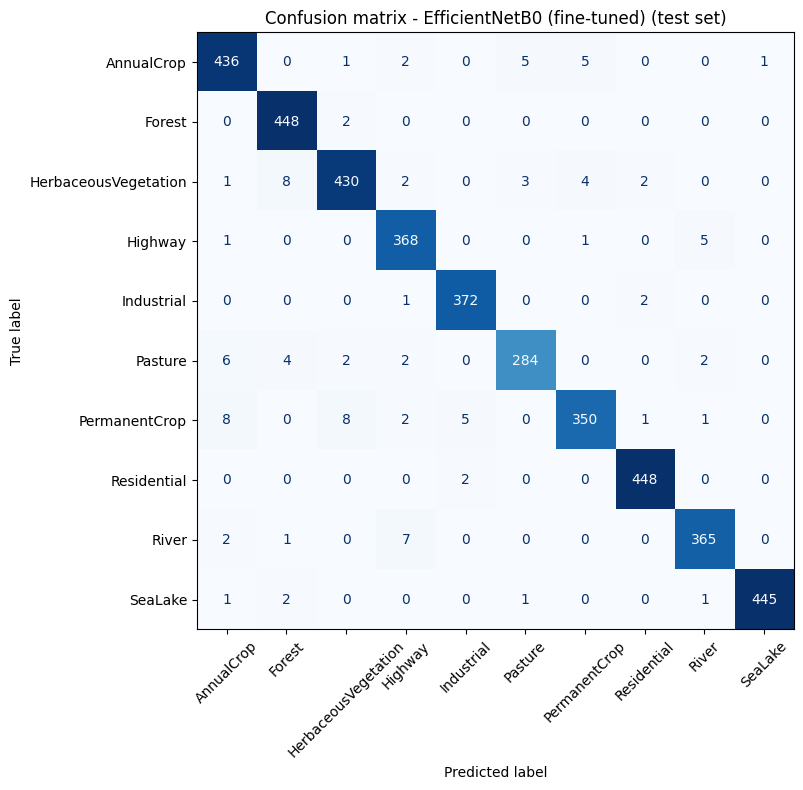

                      precision    recall  f1-score   support

          AnnualCrop      0.958     0.969     0.964       450
              Forest      0.968     0.996     0.981       450
HerbaceousVegetation      0.971     0.956     0.963       450
             Highway      0.958     0.981     0.970       375
          Industrial      0.982     0.992     0.987       375
             Pasture      0.969     0.947     0.958       300
       PermanentCrop      0.972     0.933     0.952       375
         Residential      0.989     0.996     0.992       450
               River      0.976     0.973     0.975       375
             SeaLake      0.998     0.989     0.993       450

            accuracy                          0.974      4050
           macro avg      0.974     0.973     0.973      4050
        weighted avg      0.974     0.974     0.974      4050



In [14]:
best_name = results["Macro F1"].idxmax()
best_model = models[best_name][0]
y_pred = predictions[best_name]
print("Best model:", best_name)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names, cmap="Blues",
                                        xticks_rotation=45, colorbar=False, ax=ax)
ax.set_title(f"Confusion matrix - {best_name} (test set)")
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=150)
plt.show()

print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

**Which classes get confused, and why?**

*To be filled in after running the notebook: the most frequent confusions in the matrix above,
and a likely explanation (e.g. classes that look similar at 64×64 pixels).*

## 8. Grad-CAM

Grad-CAM shows which regions of the image the model relied on: the gradients of the predicted class score
with respect to the last convolutional feature maps are averaged into one weight per feature map,
and the weighted maps are summed into a heatmap. I show 4 correctly and 2 wrongly classified test images.

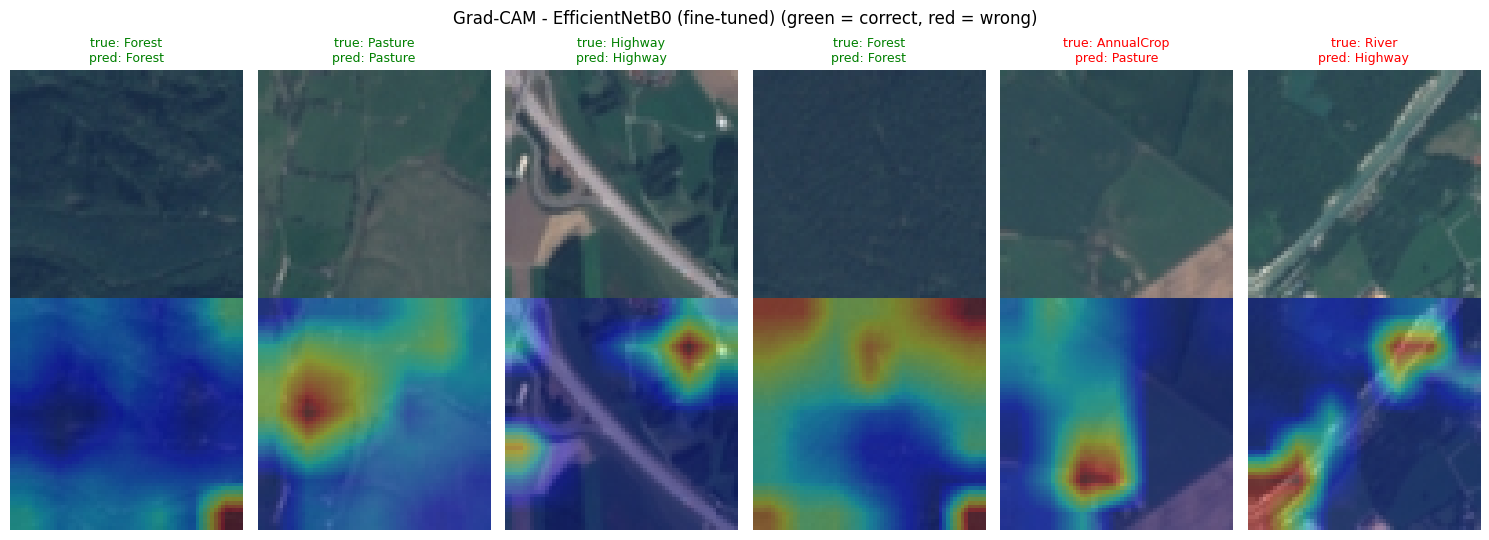

In [15]:
img_size = best_model.input_shape[1]
if best_model is tl_model:
    last_conv = "top_activation"  # last convolutional feature map of EfficientNetB0
else:
    last_conv = [layer.name for layer in best_model.layers if isinstance(layer, layers.Conv2D)][-1]

grad_model = keras.Model(best_model.inputs, [best_model.get_layer(last_conv).output, best_model.output])

def grad_cam(image):
    x = tf.image.resize(tf.cast(image[None], tf.float32), (img_size, img_size)) / 255.0
    with tf.GradientTape() as tape:
        feature_maps, preds = grad_model(x)
        score = tf.reduce_max(preds[0])  # probability of the predicted class
    grads = tape.gradient(score, feature_maps)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))  # one importance weight per feature map
    heatmap = tf.nn.relu(tf.reduce_sum(feature_maps[0] * weights, axis=-1))
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return tf.image.resize(heatmap[..., None], image.shape[:2]).numpy()[..., 0]

rng = np.random.default_rng(SEED)
correct = rng.choice(np.where(y_pred == y_test)[0], 4, replace=False)
wrong = rng.choice(np.where(y_pred != y_test)[0], 2, replace=False)

fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for col, idx in enumerate(np.concatenate([correct, wrong])):
    is_correct = y_pred[idx] == y_test[idx]
    axes[0, col].imshow(X_test[idx])
    axes[0, col].set_title(f"true: {class_names[y_test[idx]]}\npred: {class_names[y_pred[idx]]}",
                           fontsize=9, color="green" if is_correct else "red")
    axes[1, col].imshow(X_test[idx])
    axes[1, col].imshow(grad_cam(X_test[idx]), cmap="jet", alpha=0.4)
for ax in axes.flat:
    ax.axis("off")
plt.suptitle(f"Grad-CAM - {best_name} (green = correct, red = wrong)")
plt.tight_layout()
plt.savefig("figures/grad_cam.png", dpi=150)
plt.show()

## 9. Conclusion

*To be filled in after running the notebook:*

- *Effect of data augmentation (Model 1 vs Model 2):* ...
- *Transfer learning vs training from scratch:* ...
- *Hardest classes and main source of errors:* ...
- *What Grad-CAM shows about the model's decisions:* ...
- *Possible next steps:* ...

In [16]:
# Zip the figures folder so it can be downloaded in one click
shutil.make_archive("figures", "zip", "figures")
print("Saved figures.zip:", sorted(os.listdir("figures")))

try:
    from google.colab import files
    files.download("figures.zip")
except ImportError:
    pass  # not running on Colab

Saved figures.zip: ['confusion_matrix.png', 'curves_baseline_cnn.png', 'curves_cnn_augmentation.png', 'curves_efficientnetb0.png', 'grad_cam.png', 'sample_images.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>